# IA para Estatística Experimental: análises de exemplo em Python

**Curso Inova Agroflorestal (UFVJM)**: notebook de demonstração para o Google Colab.

Este notebook mostra **o código que a IA escreve "por trás"** quando você pede uma análise ao Gemini. Você **não precisa saber programar** para acompanhar: cada bloco de código vem antes de uma explicação **"O que este código faz"**.

**Como usar no Colab**
1. Clique em uma célula de código e aperte **Shift + Enter** para rodá-la (ou no botão ▶ à esquerda).
2. Rode as células **em ordem**, de cima para baixo.
3. Se algo der erro, leia a mensagem. Muitas vezes é só um arquivo que não foi carregado.

**Conjuntos de dados usados** (todos fictícios, simulados para o curso):

| Arquivo | Delineamento | Pergunta |
|---|---|---|
| `dic_mudas.csv` | DIC | Qual substrato produz mudas de ipê mais altas? |
| `dbc_milho.csv` | DBC | Qual cultivar de milho rende mais em aleias de gliricídia? |
| `fatorial_adubacao.csv` | Fatorial 3×3 em DIC | Espécie florestal × tipo de adubação: há interação? |
| `parcela_sub_cafe_sombra.csv` | Parcelas subdivididas em DBC | Sombreamento (parcela) × cultivar de café (subparcela) |
| `doses_nitrogenio.csv` | DIC com doses (regressão) | Qual a dose de N de máxima eficiência no eucalipto? |
| `dic_contagem_pragas.csv` | DIC com contagens | O que fazer quando os pressupostos da ANOVA falham? |

> Os resultados deste notebook foram conferidos com o R (pacote `ExpDes.pt`). Veja a seção **Conferência com o gabarito do R** no final.

## 0. Preparação

### 0.1 Carregar as "caixas de ferramentas" (bibliotecas)

**O que este código faz:** o Python sozinho não sabe fazer ANOVA. Aqui "abrimos as caixas de ferramentas" que já vêm instaladas no Colab:
- `pandas`: lê e organiza tabelas (como uma planilha);
- `scipy`: testes estatísticos (Shapiro-Wilk, Bartlett, Levene, Kruskal-Wallis);
- `statsmodels`: ANOVA, regressão e Tukey;
- `matplotlib`: gráficos.

In [1]:
import io
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import studentized_range
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
print("Bibliotecas carregadas!")

Bibliotecas carregadas!


### 0.2 Como carregar os dados (3 jeitos)

**O que este código faz:** cria uma função `carregar("nome_do_arquivo")` que busca a planilha em três lugares, nesta ordem:

1. **Upload do seu computador** (só no Colab): mude `USAR_UPLOAD = True`. Ao rodar cada análise, vai aparecer um botão **"Escolher arquivos"**. Aceita `.csv` ou `.xlsx`.
2. **Pasta local**: se o arquivo já estiver na pasta `dados/` (ou se você arrastou o arquivo para o painel 📁 **Arquivos** à esquerda do Colab, que fica em `/content`).
3. **Endereço na internet (URL)**: se não houver upload nem arquivo local, os dados são baixados automaticamente do repositório do curso no GitHub (`URL_BASE`). Se você copiar os arquivos para outro repositório, troque `URL_BASE` pelo endereço "raw" da sua pasta `dados/`.

> Dica: o jeito mais simples no Colab é clicar no ícone de pasta 📁 à esquerda e **arrastar os arquivos CSV para lá**.

In [2]:
# ---- AJUSTE AQUI, se precisar ----
USAR_UPLOAD = False   # True = abre a janela "Escolher arquivos" (somente no Colab)
URL_BASE = "https://raw.githubusercontent.com/guihenrique13/curso-ia-estatistica-inova-agroflorestal/main/dados/"  # endereço "raw" da pasta dados/ do repositório do curso
PASTAS_LOCAIS = ["dados", "../dados", "/content/dados", "/content"]
# -----------------------------------

EM_COLAB = "google.colab" in sys.modules


def carregar(nome):
    # 1) upload manual (Colab)
    if EM_COLAB and USAR_UPLOAD:
        from google.colab import files
        print(f"Escolha o arquivo '{nome}.csv' (ou .xlsx) no seu computador:")
        enviado = files.upload()
        nome_arquivo = list(enviado)[0]
        conteudo = io.BytesIO(enviado[nome_arquivo])
        if nome_arquivo.lower().endswith(".xlsx"):
            return pd.read_excel(conteudo)
        return pd.read_csv(conteudo)
    # 2) pasta local
    for pasta in PASTAS_LOCAIS:
        for ext in (".csv", ".xlsx"):
            caminho = os.path.join(pasta, nome + ext)
            if os.path.exists(caminho):
                print("Lido de:", caminho)
                return pd.read_csv(caminho) if ext == ".csv" else pd.read_excel(caminho)
    # 3) internet
    print("Lendo da internet:", URL_BASE + nome + ".csv")
    return pd.read_csv(URL_BASE + nome + ".csv")


print("Rodando no Colab?", EM_COLAB)

Rodando no Colab? False


### 0.3 Funções de apoio (o "molde" de cada análise)

**O que este código faz:** em vez de repetir as mesmas contas seis vezes, criamos pequenas "receitas" reaproveitáveis:

- `quadro_anova(modelo)`: monta o **quadro da ANOVA** no formato que aparece nos livros e no `ExpDes.pt` (GL, SQ, QM, Fc, Pr>Fc).
- `cv(modelo, y)`: **coeficiente de variação** (CV% = raiz do QM do resíduo ÷ média geral × 100). Mede a precisão do experimento.
- `pressupostos(modelo, dados, resposta, tratamento)`: testa **normalidade dos resíduos** (Shapiro-Wilk) e **homogeneidade das variâncias** (Bartlett e Levene). Regra prática: **p > 0,05 = pressuposto OK**.
- `tukey_letras(...)`: teste de **Tukey** com as **letras** (médias com a mesma letra não diferem). Ele recebe o QM do resíduo e o GL **do modelo correto** (importante no DBC, fatorial e parcela subdividida).

In [3]:
def quadro_anova(modelo):
    t = sm.stats.anova_lm(modelo, typ=1)
    t = t.rename(columns={"df": "GL", "sum_sq": "SQ", "mean_sq": "QM", "F": "Fc", "PR(>F)": "Pr>Fc"})
    t.index = [i.replace("C(", "").replace(")", "") for i in t.index]
    t = t.rename(index={"Residual": "Resíduo"})
    t.loc["Total"] = [t["GL"].sum(), t["SQ"].sum(), np.nan, np.nan, np.nan]
    return t


def cv(modelo, y):
    return 100 * np.sqrt(modelo.mse_resid) / np.mean(y)


def pressupostos(modelo, dados, resposta, tratamento):
    sw = stats.shapiro(modelo.resid)
    grupos = [g[resposta].to_numpy(dtype=float) for _, g in dados.groupby(tratamento)]
    bt = stats.bartlett(*grupos)
    lv = stats.levene(*grupos, center="median")
    ok = lambda p: "OK (p > 0,05)" if p > 0.05 else "VIOLADO (p <= 0,05)"
    print(f"Normalidade dos resíduos (Shapiro-Wilk): W = {sw.statistic:.4f}, p = {sw.pvalue:.4f}  -> {ok(sw.pvalue)}")
    print(f"Homogeneidade (Bartlett):                K2 = {bt.statistic:.4f}, p = {bt.pvalue:.4f}  -> {ok(bt.pvalue)}")
    print(f"Homogeneidade (Levene, mediana):         W = {lv.statistic:.4f}, p = {lv.pvalue:.4f}  -> {ok(lv.pvalue)}")
    return sw.pvalue, bt.pvalue, lv.pvalue


def tukey_letras(dados, resposta, tratamento, qme, gl_residuo, alfa=0.05):
    medias = dados.groupby(tratamento)[resposta].mean().sort_values(ascending=False)
    n = dados.groupby(tratamento)[resposta].count().min()   # repetições por tratamento
    k = len(medias)
    q = studentized_range.ppf(1 - alfa, k, gl_residuo)
    dms = q * np.sqrt(qme / n)                               # diferença mínima significativa
    m = medias.values
    letras, faixas, ultimo = [""] * k, [], -1
    for i in range(k):
        j = i
        while j + 1 < k and (m[i] - m[j + 1]) < dms:
            j += 1
        if j > ultimo:
            faixas.append((i, j))
            ultimo = j
    for f, (i, j) in enumerate(faixas):
        for t in range(i, j + 1):
            letras[t] += "abcdefghij"[f]
    print(f"Tukey a {alfa:.0%}: DMS = {dms:.4f} (q = {q:.3f}, QM resíduo = {qme:.4f}, GL = {gl_residuo:g}, n = {n})")
    return pd.DataFrame({"Média": m.round(3), "Grupo": letras}, index=medias.index)


# aqui guardamos os números principais para conferir com o R no final
conferir = {}

---
## 1. DIC: substratos para mudas de ipê-amarelo

**Experimento:** 5 substratos × 4 repetições, em delineamento inteiramente casualizado (DIC), no viveiro. Resposta: altura da muda aos 120 dias (cm).

**Modelo:** altura = média geral + efeito do substrato + erro.

### 1.1 Carregar e olhar os dados
**O que este código faz:** lê a planilha e mostra as primeiras linhas e a média por substrato. Sempre olhe os dados antes de analisar!

In [4]:
mudas = carregar("dic_mudas")
display(mudas.head())
print(mudas.groupby("substrato")["altura_cm"].agg(["count", "mean", "std"]).round(2))

Lido de: ../dados/dic_mudas.csv


,substrato,repeticao,altura_cm,diametro_mm
0,terra,1,25.9,3.20
1,terra,2,23.1,3.26
2,terra,3,29.7,3.46
3,terra,4,27.2,3.37
4,terra_esterco,1,35.3,4.16


                   count   mean   std
substrato                            
comercial              4  33.22  0.40
composto_organico      4  37.40  2.27
terra                  4  26.48  2.75
terra_areia            4  24.98  2.12
terra_esterco          4  36.35  1.13


### 1.2 ANOVA e CV
**O que este código faz:** ajusta o modelo `altura_cm ~ C(substrato)` (o `C()` diz ao Python que substrato é uma **categoria**, não um número) e monta o quadro da ANOVA.

**Como ler:** se **Pr>Fc < 0,05**, pelo menos um substrato difere dos outros.

In [5]:
mod_mudas = smf.ols("altura_cm ~ C(substrato)", data=mudas).fit()
tab = quadro_anova(mod_mudas)
display(tab)
cv_mudas = cv(mod_mudas, mudas["altura_cm"])
print(f"CV = {cv_mudas:.2f} %")
conferir["1 DIC: F substrato"] = tab.loc["substrato", "Fc"]
conferir["1 DIC: p substrato"] = tab.loc["substrato", "Pr>Fc"]
conferir["1 DIC: CV %"] = cv_mudas

,GL,SQ,QM,Fc,Pr>Fc
substrato,4.0,515.8530,128.9633,34.5731,2.0868e-07
Resíduo,15.0,55.9525,3.7302,NaN,NaN
Total,19.0,571.8055,NaN,NaN,NaN


CV = 6.10 %


### 1.3 Pressupostos
**O que este código faz:** a ANOVA só é confiável se (1) os resíduos forem aproximadamente **normais** e (2) os tratamentos tiverem **variâncias parecidas**. Os testes abaixo verificam isso.

In [6]:
sw, bt, lv = pressupostos(mod_mudas, mudas, "altura_cm", "substrato")
conferir["1 DIC: Shapiro p"] = sw
conferir["1 DIC: Bartlett p"] = bt

Normalidade dos resíduos (Shapiro-Wilk): W = 0.9725, p = 0.8071  -> OK (p > 0,05)
Homogeneidade (Bartlett):                K2 = 7.9201, p = 0.0946  -> OK (p > 0,05)
Homogeneidade (Levene, mediana):         W = 1.5202, p = 0.2464  -> OK (p > 0,05)


### 1.4 Teste de Tukey
**O que este código faz:** compara todos os pares de substratos. Primeiro com a função pronta do `statsmodels` (`pairwise_tukeyhsd`, coluna `reject = True` quer dizer "diferem"), depois em forma de **letras**, como nos artigos.

> No DIC, as duas formas dão o mesmo resultado. Em DBC/fatorial **não**: `pairwise_tukeyhsd` ignora os blocos e usa o erro errado. Por isso usamos `tukey_letras` com o QM do resíduo da ANOVA.

In [7]:
print(pairwise_tukeyhsd(mudas["altura_cm"], mudas["substrato"], alpha=0.05))
letras_mudas = tukey_letras(mudas, "altura_cm", "substrato", mod_mudas.mse_resid, mod_mudas.df_resid)
display(letras_mudas)

            Multiple Comparison of Means - Tukey HSD, FWER=0.05            
      group1            group2      meandiff p-adj   lower    upper  reject
---------------------------------------------------------------------------
        comercial composto_organico    4.175  0.053  -0.0421  8.3921  False
        comercial             terra    -6.75 0.0014 -10.9671 -2.5329   True
        comercial       terra_areia    -8.25 0.0002 -12.4671 -4.0329   True
        comercial     terra_esterco    3.125 0.2021  -1.0921  7.3421  False
composto_organico             terra  -10.925    0.0 -15.1421 -6.7079   True
composto_organico       terra_areia  -12.425    0.0 -16.6421 -8.2079   True
composto_organico     terra_esterco    -1.05 0.9357  -5.2671  3.1671  False
            terra       terra_areia     -1.5 0.8048  -5.7171  2.7171  False
            terra     terra_esterco    9.875    0.0   5.6579 14.0921   True
      terra_areia     terra_esterco   11.375    0.0   7.1579 15.5921   True
------------

Tukey a 5%: DMS = 4.2171 (q = 4.367, QM resíduo = 3.7302, GL = 15, n = 4)


,Média,Grupo
substrato,,
composto_organico,37.400,a
terra_esterco,36.350,a
comercial,33.225,a
terra,26.475,b
terra_areia,24.975,b


### 1.5 Gráfico
**O que este código faz:** gráfico de barras com a média de cada substrato, o desvio padrão (barrinha preta) e as letras do Tukey em cima.

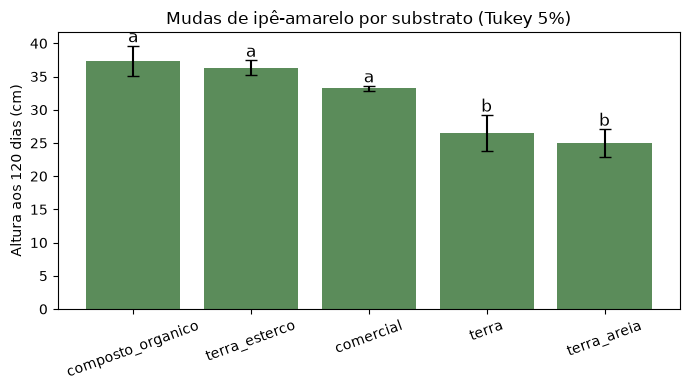

In [8]:
resumo = mudas.groupby("substrato")["altura_cm"].agg(["mean", "std"]).loc[letras_mudas.index]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(resumo.index, resumo["mean"], yerr=resumo["std"], capsize=4, color="#5b8c5a")
for i, (nome, linha) in enumerate(resumo.iterrows()):
    ax.text(i, linha["mean"] + linha["std"] + 0.5, letras_mudas.loc[nome, "Grupo"], ha="center", fontsize=12)
ax.set_ylabel("Altura aos 120 dias (cm)")
ax.set_title("Mudas de ipê-amarelo por substrato (Tukey 5%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Interpretação:** composto orgânico, terra + esterco e substrato comercial formam o grupo "a" (mudas mais altas); terra pura e terra + areia ficam no grupo "b". CV de 6,1% indica **boa precisão**.

---
## 2. DBC: cultivares de milho em aleias de gliricídia

**Experimento:** 5 cultivares × 4 blocos (os blocos são faixas do terreno com declives diferentes). Resposta: produtividade de grãos (kg/ha).

**Por que blocos?** O terreno não é uniforme. Cada bloco tem **todas** as cultivares, e o modelo "desconta" a diferença entre blocos do erro, o que deixa o teste mais sensível.

**Modelo:** produtividade = média + efeito da cultivar + efeito do bloco + erro.

In [9]:
milho = carregar("dbc_milho")
display(milho.head())
print(milho.pivot(index="cultivar", columns="bloco", values="produtividade_kg_ha"))

Lido de: ../dados/dbc_milho.csv


,bloco,cultivar,produtividade_kg_ha
0,1,BRS_Caimbe,5603
1,2,BRS_Caimbe,5157
2,3,BRS_Caimbe,4835
3,4,BRS_Caimbe,5256
4,1,AL_Bandeirante,5304


bloco                 1     2     3     4
cultivar                                 
AL_Bandeirante     5304  5107  5218  4268
BRS_Caimbe         5603  5157  4835  5256
BRS_Gorutuba       6615  6539  5871  5495
Crioulo_local      4477  4679  4035  3974
Hibrido_comercial  6374  6294  6285  5636


### 2.1 ANOVA e CV
**O que este código faz:** igual ao DIC, mas agora o modelo tem `+ C(bloco)`.

In [10]:
mod_milho = smf.ols("produtividade_kg_ha ~ C(cultivar) + C(bloco)", data=milho).fit()
tab = quadro_anova(mod_milho)
display(tab)
cv_milho = cv(mod_milho, milho["produtividade_kg_ha"])
print(f"CV = {cv_milho:.2f} %")
conferir["2 DBC: F cultivar"] = tab.loc["cultivar", "Fc"]
conferir["2 DBC: p cultivar"] = tab.loc["cultivar", "Pr>Fc"]
conferir["2 DBC: F bloco"] = tab.loc["bloco", "Fc"]
conferir["2 DBC: CV %"] = cv_milho

,GL,SQ,QM,Fc,Pr>Fc
cultivar,4.0,1.0100e+07,2.5250e+06,34.6863,1.6597e-06
bloco,3.0,1.6883e+06,5.6276e+05,7.7307,3.8762e-03
Resíduo,12.0,8.7354e+05,7.2795e+04,NaN,NaN
Total,19.0,1.2662e+07,NaN,NaN,NaN


CV = 5.04 %


### 2.2 Pressupostos
> Observação: o `ExpDes.pt` usa, no DBC, o teste de O'Neill-Mathews para homogeneidade. Aqui mostramos Bartlett e Levene, que são os mais comuns. A conclusão é a mesma (variâncias homogêneas).

In [11]:
sw, bt, lv = pressupostos(mod_milho, milho, "produtividade_kg_ha", "cultivar")
conferir["2 DBC: Shapiro p"] = sw

Normalidade dos resíduos (Shapiro-Wilk): W = 0.9462, p = 0.3133  -> OK (p > 0,05)
Homogeneidade (Bartlett):                K2 = 1.2240, p = 0.8741  -> OK (p > 0,05)
Homogeneidade (Levene, mediana):         W = 0.5920, p = 0.6737  -> OK (p > 0,05)


### 2.3 Tukey (com o erro do DBC)
**O que este código faz:** Tukey usando o **QM do resíduo e o GL da ANOVA do DBC** (12 GL), e não o erro de uma ANOVA simples.

In [12]:
letras_milho = tukey_letras(milho, "produtividade_kg_ha", "cultivar", mod_milho.mse_resid, mod_milho.df_resid)
display(letras_milho)

Tukey a 5%: DMS = 608.1013 (q = 4.508, QM resíduo = 72794.7333, GL = 12, n = 4)


,Média,Grupo
cultivar,,
Hibrido_comercial,6147.25,a
BRS_Gorutuba,6130.00,a
BRS_Caimbe,5212.75,b
AL_Bandeirante,4974.25,b
Crioulo_local,4291.25,c


### 2.4 Gráfico
**O que este código faz:** mostra a produtividade de cada cultivar **em cada bloco** (pontos ligados por linha). Se as linhas andam "juntas", o efeito do bloco é parecido para todas as cultivares.

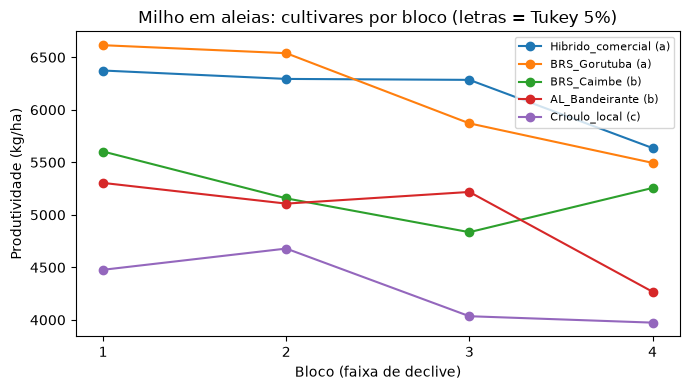

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
for cult in letras_milho.index:
    sub = milho[milho["cultivar"] == cult].sort_values("bloco")
    ax.plot(sub["bloco"], sub["produtividade_kg_ha"], marker="o",
            label=f"{cult} ({letras_milho.loc[cult, 'Grupo']})")
ax.set_xticks([1, 2, 3, 4])
ax.set_xlabel("Bloco (faixa de declive)")
ax.set_ylabel("Produtividade (kg/ha)")
ax.set_title("Milho em aleias: cultivares por bloco (letras = Tukey 5%)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretação:** Híbrido comercial e BRS Gorutuba são os mais produtivos (grupo "a"); o milho crioulo fica sozinho no grupo "c". O efeito de bloco também foi significativo, o que mostra que **usar blocos valeu a pena**.

---
## 3. Fatorial 3×3 em DIC: espécie florestal × adubação

**Experimento:** 3 espécies (angico, aroeira, mogno-africano) × 3 adubações (sem adubo, orgânico, mineral) × 4 repetições = 36 vasos. Resposta: massa seca aos 6 meses (g).

**A grande pergunta do fatorial é a INTERAÇÃO:** o efeito da adubação **depende** da espécie? Se a interação for significativa, não dá para falar "o melhor adubo" de forma geral. É preciso fazer o **desdobramento** (analisar um fator **dentro** de cada nível do outro).

In [14]:
fat = carregar("fatorial_adubacao")
display(fat.head())
print(fat.pivot_table(index="especie", columns="adubacao", values="massa_seca_g", aggfunc="mean").round(2))

Lido de: ../dados/fatorial_adubacao.csv


,especie,adubacao,repeticao,massa_seca_g
0,angico,sem_adubo,1,16.2
1,angico,sem_adubo,2,16.2
2,angico,sem_adubo,3,16.3
3,angico,sem_adubo,4,15.4
4,angico,organico,1,24.4


adubacao        mineral  organico  sem_adubo
especie                                     
angico            23.42     26.02      16.02
aroeira           15.58     17.12      15.48
mogno_africano    33.60     28.32      20.23


### 3.1 ANOVA com interação e CV
**O que este código faz:** `C(especie) * C(adubacao)` inclui os dois efeitos principais **e** a interação `especie:adubacao`.

In [15]:
mod_fat = smf.ols("massa_seca_g ~ C(especie) * C(adubacao)", data=fat).fit()
tab = quadro_anova(mod_fat)
display(tab)
cv_fat = cv(mod_fat, fat["massa_seca_g"])
print(f"CV = {cv_fat:.2f} %")
QME_fat, GL_fat = mod_fat.mse_resid, mod_fat.df_resid
conferir["3 Fatorial: F especie"] = tab.loc["especie", "Fc"]
conferir["3 Fatorial: F adubacao"] = tab.loc["adubacao", "Fc"]
conferir["3 Fatorial: F interacao"] = tab.loc["especie:adubacao", "Fc"]
conferir["3 Fatorial: p interacao"] = tab.loc["especie:adubacao", "Pr>Fc"]
conferir["3 Fatorial: CV %"] = cv_fat

,GL,SQ,QM,Fc,Pr>Fc
especie,2.0,769.6206,384.8103,111.0979,9.3349e-14
adubacao,2.0,367.5972,183.7986,53.0642,4.4234e-10
especie:adubacao,4.0,217.7111,54.4278,15.7138,9.3204e-07
Resíduo,27.0,93.5200,3.4637,NaN,NaN
Total,35.0,1448.4489,NaN,NaN,NaN


CV = 8.55 %


### 3.2 Pressupostos

In [16]:
fat["tratamento"] = fat["especie"] + " | " + fat["adubacao"]
sw, bt, lv = pressupostos(mod_fat, fat, "massa_seca_g", "tratamento")
conferir["3 Fatorial: Shapiro p"] = sw

Normalidade dos resíduos (Shapiro-Wilk): W = 0.9726, p = 0.5000  -> OK (p > 0,05)
Homogeneidade (Bartlett):                K2 = 9.0251, p = 0.3402  -> OK (p > 0,05)
Homogeneidade (Levene, mediana):         W = 1.4501, p = 0.2217  -> OK (p > 0,05)


### 3.3 Gráfico de interação
**O que este código faz:** uma linha por espécie. **Linhas paralelas = sem interação. Linhas que se cruzam ou abrem = interação.** Aqui o mogno dispara com adubo mineral, enquanto a aroeira quase não responde.

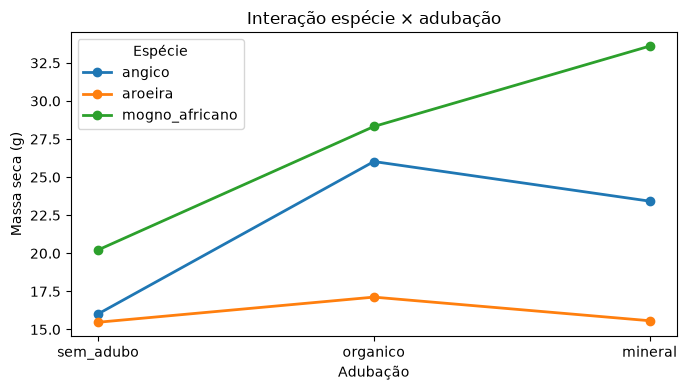

In [17]:
ordem_adubo = ["sem_adubo", "organico", "mineral"]
medias_fat = fat.groupby(["especie", "adubacao"])["massa_seca_g"].mean().unstack()[ordem_adubo]
fig, ax = plt.subplots(figsize=(7, 4))
for esp, linha in medias_fat.iterrows():
    ax.plot(ordem_adubo, linha.values, marker="o", linewidth=2, label=esp)
ax.set_xlabel("Adubação")
ax.set_ylabel("Massa seca (g)")
ax.set_title("Interação espécie × adubação")
ax.legend(title="Espécie")
plt.tight_layout()
plt.show()

### 3.4 Desdobramento da interação
**O que este código faz:** como a interação foi significativa, para **cada nível de um fator** fazemos uma "mini-ANOVA" do outro fator, sempre usando o **QM do resíduo da ANOVA completa** (27 GL). Se o F do desdobramento for significativo, aplicamos Tukey naquele nível.

Conta da soma de quadrados dentro de um nível: SQ = n × Σ (média da combinação − média do nível)², com n = 4 repetições.

In [18]:
def desdobrar(dados, resposta, fator, dentro, qme, gl, alfa=0.05):
    linhas = []
    for nivel, sub in dados.groupby(dentro):
        medias = sub.groupby(fator)[resposta].mean()
        n = sub.groupby(fator)[resposta].count().iloc[0]
        sq = n * ((medias - sub[resposta].mean()) ** 2).sum()
        glf = len(medias) - 1
        F = (sq / glf) / qme
        p = stats.f.sf(F, glf, gl)
        linhas.append({"Fonte": f"{fator} dentro de {dentro} = {nivel}", "GL": glf, "SQ": sq,
                       "QM": sq / glf, "Fc": F, "Pr>Fc": p})
    tabela = pd.DataFrame(linhas).set_index("Fonte")
    display(tabela.round(4))
    for (nivel, sub), p in zip(dados.groupby(dentro), tabela["Pr>Fc"]):
        print(f"\n>> {fator} dentro de {dentro} = {nivel}")
        if p < alfa:
            display(tukey_letras(sub, resposta, fator, qme, gl, alfa))
        else:
            print("   F não significativo: as médias são estatisticamente iguais.")
            print(sub.groupby(fator)[resposta].mean().round(3).to_string())
    return tabela


print("=== Espécie dentro de cada adubação ===")
d1 = desdobrar(fat, "massa_seca_g", "especie", "adubacao", QME_fat, GL_fat)

=== Espécie dentro de cada adubação ===


,GL,SQ,QM,Fc,Pr>Fc
Fonte,,,,,
especie dentro de adubacao = mineral,2,653.4050,326.7025,94.3217,0.0000
especie dentro de adubacao = organico,2,279.9200,139.9600,40.4076,0.0000
especie dentro de adubacao = sem_adubo,2,54.0067,27.0033,7.7961,0.0021



>> especie dentro de adubacao = mineral


Tukey a 5%: DMS = 3.2629 (q = 3.506, QM resíduo = 3.4637, GL = 27, n = 4)


,Média,Grupo
especie,,
mogno_africano,33.600,a
angico,23.425,b
aroeira,15.575,c



>> especie dentro de adubacao = organico


Tukey a 5%: DMS = 3.2629 (q = 3.506, QM resíduo = 3.4637, GL = 27, n = 4)


,Média,Grupo
especie,,
mogno_africano,28.325,a
angico,26.025,a
aroeira,17.125,b



>> especie dentro de adubacao = sem_adubo
Tukey a 5%: DMS = 3.2629 (q = 3.506, QM resíduo = 3.4637, GL = 27, n = 4)


,Média,Grupo
especie,,
mogno_africano,20.225,a
angico,16.025,b
aroeira,15.475,b


In [19]:
print("=== Adubação dentro de cada espécie ===")
d2 = desdobrar(fat, "massa_seca_g", "adubacao", "especie", QME_fat, GL_fat)
conferir["3 Fatorial: F esp. d/ mineral"] = d1.loc["especie dentro de adubacao = mineral", "Fc"]
conferir["3 Fatorial: F adub. d/ aroeira"] = d2.loc["adubacao dentro de especie = aroeira", "Fc"]
conferir["3 Fatorial: p adub. d/ aroeira"] = d2.loc["adubacao dentro de especie = aroeira", "Pr>Fc"]

=== Adubação dentro de cada espécie ===


,GL,SQ,QM,Fc,Pr>Fc
Fonte,,,,,
adubacao dentro de especie = angico,2,215.3600,107.6800,31.0881,0.0000
adubacao dentro de especie = aroeira,2,6.8467,3.4233,0.9883,0.3853
adubacao dentro de especie = mogno_africano,2,363.1017,181.5508,52.4152,0.0000



>> adubacao dentro de especie = angico


Tukey a 5%: DMS = 3.2629 (q = 3.506, QM resíduo = 3.4637, GL = 27, n = 4)


,Média,Grupo
adubacao,,
organico,26.025,a
mineral,23.425,a
sem_adubo,16.025,b



>> adubacao dentro de especie = aroeira
   F não significativo: as médias são estatisticamente iguais.
adubacao
mineral      15.575
organico     17.125
sem_adubo    15.475

>> adubacao dentro de especie = mogno_africano


Tukey a 5%: DMS = 3.2629 (q = 3.506, QM resíduo = 3.4637, GL = 27, n = 4)


,Média,Grupo
adubacao,,
mineral,33.600,a
organico,28.325,b
sem_adubo,20.225,c


**Interpretação:** o mogno-africano é a espécie que mais acumula massa em todas as adubações e responde **mais ao adubo mineral** (a > b > c). O angico responde igualmente ao orgânico e ao mineral. A **aroeira não responde à adubação** (p = 0,385). Por isso uma recomendação única de adubo estaria errada.

---
## 4. Parcelas subdivididas em DBC: sombreamento × cultivar de café

**Experimento:** 4 blocos. Em cada bloco, 3 **parcelas** recebem um nível de sombreamento por árvores (0, 30 e 50%). Cada parcela é dividida em 3 **subparcelas** com as cultivares de café (Catuaí 144, Arara, Topázio). Resposta: produtividade (sacas/ha).

**Por que é diferente do fatorial comum?** O sombreamento é aplicado em áreas grandes (não dá para sombrear uma linha só de café). Então existem **dois erros**:
- **Erro (a)** = bloco × sombreamento → usado para testar **sombreamento** (e bloco). Tem só 6 GL!
- **Erro (b)** = resíduo → usado para testar **cultivar** e a **interação**.

> Erro comum (inclusive de IAs!): analisar como fatorial simples e testar o sombreamento com o resíduo. Isso dá um F inflado e conclusões erradas.

In [20]:
cafe = carregar("parcela_sub_cafe_sombra")
cafe["sombreamento_pct"] = cafe["sombreamento_pct"].astype(str)   # tratar como categoria
display(cafe.head())
print(cafe.pivot_table(index="sombreamento_pct", columns="cultivar", values="produtividade_sc_ha", aggfunc="mean").round(2))

Lido de: ../dados/parcela_sub_cafe_sombra.csv


,bloco,sombreamento_pct,cultivar,produtividade_sc_ha
0,1,0,Catuai_144,28.6
1,1,0,Arara,30.6
2,1,0,Topazio,23.1
3,1,30,Catuai_144,32.9
4,1,30,Arara,33.5


cultivar          Arara  Catuai_144  Topazio
sombreamento_pct                            
0                 33.15       31.05    25.45
30                35.75       34.62    32.48
50                36.97       32.28    29.50


### 4.1 ANOVA com os dois erros (cálculo manual)
**O que este código faz:**
1. Ajusta um modelo com todos os termos, incluindo `bloco:sombreamento` (que é o erro a).
2. Pega as somas de quadrados desse quadro.
3. **Refaz os testes F**: sombreamento e bloco divididos pelo QM do **erro (a)**; cultivar e interação divididos pelo QM do **erro (b)**.
4. Calcula dois CVs: CV 1 (parcelas, erro a) e CV 2 (subparcelas, erro b).

In [21]:
mod_cafe = smf.ols("produtividade_sc_ha ~ C(bloco) + C(sombreamento_pct) + C(bloco):C(sombreamento_pct)"
                   " + C(cultivar) + C(sombreamento_pct):C(cultivar)", data=cafe).fit()
bruto = sm.stats.anova_lm(mod_cafe, typ=1)
gl, sq = bruto["df"], bruto["sum_sq"]
nomes = {"C(bloco)": "Bloco", "C(sombreamento_pct)": "Sombreamento", "C(bloco):C(sombreamento_pct)": "Erro a",
         "C(cultivar)": "Cultivar", "C(sombreamento_pct):C(cultivar)": "Sombreamento x Cultivar", "Residual": "Erro b"}
gl, sq = gl.rename(nomes), sq.rename(nomes)
qm = sq / gl
QMa, GLa, QMb, GLb = qm["Erro a"], gl["Erro a"], qm["Erro b"], gl["Erro b"]

linhas = []
for fonte, erro in [("Sombreamento", "a"), ("Bloco", "a"), ("Erro a", None),
                    ("Cultivar", "b"), ("Sombreamento x Cultivar", "b"), ("Erro b", None)]:
    if erro is None:
        F = p = np.nan
    else:
        qme, gle = (QMa, GLa) if erro == "a" else (QMb, GLb)
        F = qm[fonte] / qme
        p = stats.f.sf(F, gl[fonte], gle)
    linhas.append({"Fonte": fonte, "GL": gl[fonte], "SQ": sq[fonte], "QM": qm[fonte], "Fc": F, "Pr>Fc": p,
                   "Testado contra": {"a": "Erro a", "b": "Erro b", None: ""}[erro]})
linhas.append({"Fonte": "Total", "GL": gl.sum(), "SQ": sq.sum(), "QM": np.nan, "Fc": np.nan, "Pr>Fc": np.nan, "Testado contra": ""})
tab_cafe = pd.DataFrame(linhas).set_index("Fonte")
display(tab_cafe.round(4))

media_geral = cafe["produtividade_sc_ha"].mean()
cv1, cv2 = 100 * np.sqrt(QMa) / media_geral, 100 * np.sqrt(QMb) / media_geral
print(f"CV 1 (parcelas, erro a)    = {cv1:.2f} %")
print(f"CV 2 (subparcelas, erro b) = {cv2:.2f} %")

conferir["4 Subdividida: F sombreamento"] = tab_cafe.loc["Sombreamento", "Fc"]
conferir["4 Subdividida: p sombreamento"] = tab_cafe.loc["Sombreamento", "Pr>Fc"]
conferir["4 Subdividida: F bloco"] = tab_cafe.loc["Bloco", "Fc"]
conferir["4 Subdividida: F cultivar"] = tab_cafe.loc["Cultivar", "Fc"]
conferir["4 Subdividida: F interacao"] = tab_cafe.loc["Sombreamento x Cultivar", "Fc"]
conferir["4 Subdividida: p interacao"] = tab_cafe.loc["Sombreamento x Cultivar", "Pr>Fc"]
conferir["4 Subdividida: CV1 %"] = cv1
conferir["4 Subdividida: CV2 %"] = cv2

,GL,SQ,QM,Fc,Pr>Fc,Testado contra
Fonte,,,,,,
Sombreamento,2.0,121.7156,60.8578,6.4770,0.0317,Erro a
Bloco,3.0,123.3611,41.1204,4.3764,0.0590,Erro a
Erro a,6.0,56.3756,9.3959,NaN,NaN,
Cultivar,2.0,228.4372,114.2186,78.6108,0.0000,Erro b
Sombreamento x Cultivar,4.0,34.6828,8.6707,5.9676,0.0031,Erro b
Erro b,18.0,26.1533,1.4530,NaN,NaN,
Total,35.0,590.7256,NaN,NaN,NaN,


CV 1 (parcelas, erro a)    = 9.47 %
CV 2 (subparcelas, erro b) = 3.72 %


**Para comparar:** se tivéssemos (erradamente) testado o sombreamento contra o erro b, o F seria muito maior. Veja:

In [22]:
F_errado = qm["Sombreamento"] / QMb
print(f"F do sombreamento com erro ERRADO (erro b): {F_errado:.2f}  p = {stats.f.sf(F_errado, 2, GLb):.2e}")
print(f"F do sombreamento com erro CERTO (erro a):  {tab_cafe.loc['Sombreamento', 'Fc']:.2f}  p = {tab_cafe.loc['Sombreamento', 'Pr>Fc']:.4f}")

F do sombreamento com erro ERRADO (erro b): 41.89  p = 1.69e-07
F do sombreamento com erro CERTO (erro a):  6.48  p = 0.0317


### 4.2 (Alternativa) Modelo misto
**O que este código faz:** outra forma moderna de analisar parcela subdividida é o **modelo misto**, em que a parcela (bloco × sombreamento) entra como **efeito aleatório**. O teste de Wald conjunto para o sombreamento deve concordar em linhas gerais com o cálculo manual (com dados balanceados, os F dos efeitos de subparcela coincidem).

In [23]:
cafe["parcela"] = cafe["bloco"].astype(str) + "_" + cafe["sombreamento_pct"]
misto = smf.mixedlm("produtividade_sc_ha ~ C(bloco) + C(sombreamento_pct) * C(cultivar)",
                    data=cafe, groups=cafe["parcela"]).fit(reml=True)
print(f"Variância entre parcelas (erro a, componente): {misto.cov_re.iloc[0, 0]:.3f}")
print(f"Variância residual (erro b):                   {misto.scale:.3f}")
print(f"Conferência: (QM erro a - QM erro b) / 3 = {(QMa - QMb) / 3:.3f}  |  QM erro b = {QMb:.3f}")

Variância entre parcelas (erro a, componente): 2.648
Variância residual (erro b):                   1.453
Conferência: (QM erro a - QM erro b) / 3 = 2.648  |  QM erro b = 1.453


### 4.3 Desdobramento da interação
**O que este código faz:**
- **Cultivar dentro de cada sombreamento:** usa o **erro b** (18 GL), com a mesma função `desdobrar` do fatorial.
- **Sombreamento dentro de cada cultivar:** mistura parcelas diferentes, então usa um **erro combinado** = (QMa + (c − 1)·QMb) / c, onde c = 3 cultivares, com GL calculado pela fórmula de **Satterthwaite**. É exatamente o que o `ExpDes.pt` faz.

In [24]:
print("=== Cultivar dentro de cada sombreamento (erro b) ===")
d_cult = desdobrar(cafe, "produtividade_sc_ha", "cultivar", "sombreamento_pct", QMb, GLb)

=== Cultivar dentro de cada sombreamento (erro b) ===


,GL,SQ,QM,Fc,Pr>Fc
Fonte,,,,,
cultivar dentro de sombreamento_pct = 0,2,126.7467,63.3733,43.6166,0.000
cultivar dentro de sombreamento_pct = 30,2,22.1517,11.0758,7.6229,0.004
cultivar dentro de sombreamento_pct = 50,2,114.2217,57.1108,39.3065,0.000



>> cultivar dentro de sombreamento_pct = 0


Tukey a 5%: DMS = 2.1753 (q = 3.609, QM resíduo = 1.4530, GL = 18, n = 4)


,Média,Grupo
cultivar,,
Arara,33.15,a
Catuai_144,31.05,a
Topazio,25.45,b


...

Tukey a 5%: DMS = 2.1753 (q = 3.609, QM resíduo = 1.4530, GL = 18, n = 4)


,Média,Grupo
cultivar,,
Arara,35.750,a
Catuai_144,34.625,ab
Topazio,32.475,b



>> cultivar dentro de sombreamento_pct = 50


Tukey a 5%: DMS = 2.1753 (q = 3.609, QM resíduo = 1.4530, GL = 18, n = 4)


,Média,Grupo
cultivar,,
Arara,36.975,a
Catuai_144,32.275,b
Topazio,29.500,c


In [25]:
c = cafe["cultivar"].nunique()
QM_comb = (QMa + (c - 1) * QMb) / c
GL_comb = (QMa + (c - 1) * QMb) ** 2 / (QMa ** 2 / GLa + ((c - 1) * QMb) ** 2 / GLb)
print(f"Erro combinado: QM = {QM_comb:.4f}, GL (Satterthwaite) = {GL_comb:.3f}\n")
print("=== Sombreamento dentro de cada cultivar (erro combinado) ===")
d_somb = desdobrar(cafe, "produtividade_sc_ha", "sombreamento_pct", "cultivar", QM_comb, GL_comb)
conferir["4 Subdividida: F somb. d/ Topazio"] = d_somb.loc["sombreamento_pct dentro de cultivar = Topazio", "Fc"]
conferir["4 Subdividida: F cult. d/ 30%"] = d_cult.loc["cultivar dentro de sombreamento_pct = 30", "Fc"]

Erro combinado: QM = 4.1006, GL (Satterthwaite) = 9.967

=== Sombreamento dentro de cada cultivar (erro combinado) ===


,GL,SQ,QM,Fc,Pr>Fc
Fonte,,,,,
sombreamento_pct dentro de cultivar = Arara,2,30.5217,15.2608,3.7216,0.0621
sombreamento_pct dentro de cultivar = Catuai_144,2,26.4050,13.2025,3.2196,0.0834
sombreamento_pct dentro de cultivar = Topazio,2,99.4717,49.7358,12.1289,0.0021



>> sombreamento_pct dentro de cultivar = Arara
   F não significativo: as médias são estatisticamente iguais.
sombreamento_pct
0     33.150
30    35.750
50    36.975

>> sombreamento_pct dentro de cultivar = Catuai_144
   F não significativo: as médias são estatisticamente iguais.
sombreamento_pct
0     31.050
30    34.625
50    32.275

>> sombreamento_pct dentro de cultivar = Topazio


Tukey a 5%: DMS = 3.9273 (q = 3.879, QM resíduo = 4.1006, GL = 9.96741, n = 4)


,Média,Grupo
sombreamento_pct,,
30,32.475,a
50,29.500,a
0,25.450,b


> Como o sombreamento é **quantitativo** (0, 30, 50%), o `ExpDes.pt` ajusta uma regressão para a Topázio em vez do Tukey. Com apenas 3 níveis, o mais honesto é descrever a tendência: a Topázio produz mais com sombra.

### 4.4 Gráfico

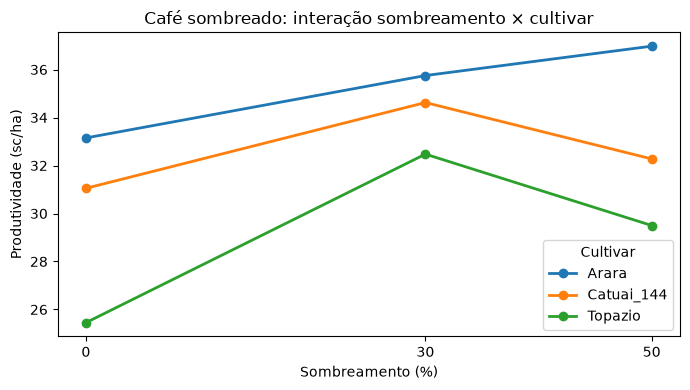

In [26]:
ordem_s = ["0", "30", "50"]
medias_cafe = cafe.groupby(["cultivar", "sombreamento_pct"])["produtividade_sc_ha"].mean().unstack()[ordem_s]
fig, ax = plt.subplots(figsize=(7, 4))
for cult, linha in medias_cafe.iterrows():
    ax.plot([0, 30, 50], linha.values, marker="o", linewidth=2, label=cult)
ax.set_xticks([0, 30, 50])
ax.set_xlabel("Sombreamento (%)")
ax.set_ylabel("Produtividade (sc/ha)")
ax.set_title("Café sombreado: interação sombreamento × cultivar")
ax.legend(title="Cultivar")
plt.tight_layout()
plt.show()

**Interpretação:** o sombreamento tem efeito significativo (p = 0,032, testado corretamente com o erro a). A interação é significativa: a **Arara** é sempre a melhor ou empatada, e a **Topázio** é a mais prejudicada a pleno sol, melhorando com sombra.

---
## 5. Regressão: doses de nitrogênio no eucalipto (ILPF)

**Experimento:** 5 doses de N em cobertura (0, 50, 100, 150, 200 kg/ha) × 4 repetições em DIC. Resposta: volume de madeira (m³/ha).

**Por que regressão e não Tukey?** Dose é um número. Perguntar "a dose 100 difere da 150?" desperdiça informação. O certo é ajustar uma **curva** e achar a **dose de máxima eficiência técnica (MET)**.

Modelo quadrático: volume = b0 + b1·dose + b2·dose². Se b2 < 0, a curva tem um ponto máximo em **MET = −b1 / (2·b2)**.

In [27]:
doses = carregar("doses_nitrogenio")
display(doses.head())
print(doses.groupby("dose_n_kg_ha")["volume_m3_ha"].mean().round(2))

Lido de: ../dados/doses_nitrogenio.csv


,dose_n_kg_ha,repeticao,volume_m3_ha
0,0,1,41.9
1,0,2,42.4
2,0,3,39.6
3,0,4,41.5
4,50,1,51.0


dose_n_kg_ha
0      41.35
50     50.38
100    55.97
150    60.75
200    59.00
Name: volume_m3_ha, dtype: float64


### 5.1 ANOVA (dose como categoria), pressupostos e CV

In [28]:
mod_dose_cat = smf.ols("volume_m3_ha ~ C(dose_n_kg_ha)", data=doses).fit()
tab = quadro_anova(mod_dose_cat)
display(tab)
cv_dose = cv(mod_dose_cat, doses["volume_m3_ha"])
print(f"CV = {cv_dose:.2f} %")
sw, bt, lv = pressupostos(mod_dose_cat, doses, "volume_m3_ha", "dose_n_kg_ha")
QME_d, GL_d, SQ_trat = mod_dose_cat.mse_resid, mod_dose_cat.df_resid, tab.iloc[0]["SQ"]
conferir["5 Doses: F tratamento"] = tab.iloc[0]["Fc"]
conferir["5 Doses: CV %"] = cv_dose

,GL,SQ,QM,Fc,Pr>Fc
dose_n_kg_ha,4.0,985.303,246.3258,32.5498,3.1179e-07
Resíduo,15.0,113.515,7.5677,NaN,NaN
Total,19.0,1098.818,NaN,NaN,NaN


CV = 5.14 %
Normalidade dos resíduos (Shapiro-Wilk): W = 0.9612, p = 0.5688  -> OK (p > 0,05)
Homogeneidade (Bartlett):                K2 = 2.9693, p = 0.5630  -> OK (p > 0,05)
Homogeneidade (Levene, mediana):         W = 0.4551, p = 0.7674  -> OK (p > 0,05)


### 5.2 Regressões linear e quadrática
**O que este código faz:** ajusta as duas curvas, decompõe a soma de quadrados dos tratamentos em **efeito linear**, **efeito quadrático** e **desvios da regressão**, e testa cada parte com o QM do resíduo da ANOVA (como no `ExpDes.pt`/SISVAR).

- O **R²** é calculado sobre as **médias** das doses (SQ da regressão ÷ SQ de tratamentos), como no `ExpDes.pt`.
- **Desvios não significativos** = a curva explica bem as médias.

In [29]:
lin = smf.ols("volume_m3_ha ~ dose_n_kg_ha", data=doses).fit()
quad = smf.ols("volume_m3_ha ~ dose_n_kg_ha + I(dose_n_kg_ha**2)", data=doses).fit()
print("Linear:     ", lin.params.round(5).to_dict())
print("Quadrático: ", quad.params.round(6).to_dict())

sq_lin = lin.ess
sq_quad = quad.ess - lin.ess
sq_desv = SQ_trat - quad.ess
decomp = pd.DataFrame({
    "GL": [1, 1, 2, GL_d],
    "SQ": [sq_lin, sq_quad, sq_desv, QME_d * GL_d],
}, index=["Efeito linear", "Efeito quadrático", "Desvios da regressão", "Resíduo"])
decomp["QM"] = decomp["SQ"] / decomp["GL"]
decomp["Fc"] = decomp["QM"] / QME_d
decomp["Pr>Fc"] = stats.f.sf(decomp["Fc"], decomp["GL"], GL_d)
decomp.loc["Resíduo", ["Fc", "Pr>Fc"]] = np.nan
display(decomp.round(4))

r2_lin, r2_quad = sq_lin / SQ_trat, quad.ess / SQ_trat
b0, b1, b2 = quad.params
MET = -b1 / (2 * b2)
vol_max = b0 + b1 * MET + b2 * MET ** 2
print(f"R² linear = {r2_lin:.4f} | R² quadrático = {r2_quad:.4f}")
print(f"Equação: volume = {b0:.4f} + {b1:.5f}·dose {b2:+.7f}·dose²")
print(f"Dose de máxima eficiência técnica (MET) = {MET:.1f} kg/ha de N  ->  volume estimado = {vol_max:.1f} m³/ha")

conferir["5 Doses: F efeito linear"] = decomp.loc["Efeito linear", "Fc"]
conferir["5 Doses: F efeito quadratico"] = decomp.loc["Efeito quadrático", "Fc"]
conferir["5 Doses: R2 quadratico"] = r2_quad
conferir["5 Doses: b1"] = b1
conferir["5 Doses: MET kg/ha"] = MET

Linear:      {'Intercept': 44.355, 'dose_n_kg_ha': 0.09135}
Quadrático:  {'Intercept': 41.158571, 'dose_n_kg_ha': 0.219207, 'I(dose_n_kg_ha ** 2)': -0.000639}


,GL,SQ,QM,Fc,Pr>Fc
Efeito linear,1.0,834.4823,834.4823,110.2694,0.0000
Efeito quadrático,1.0,143.0402,143.0402,18.9015,0.0006
Desvios da regressão,2.0,7.7806,3.8903,0.5141,0.6082
Resíduo,15.0,113.5150,7.5677,NaN,NaN


R² linear = 0.8469 | R² quadrático = 0.9921
Equação: volume = 41.1586 + 0.21921·dose -0.0006393·dose²
Dose de máxima eficiência técnica (MET) = 171.4 kg/ha de N  ->  volume estimado = 59.9 m³/ha


### 5.3 Gráfico
**O que este código faz:** pontos = parcelas; quadrados = médias; linha = curva quadrática; tracejado = dose de máxima eficiência.

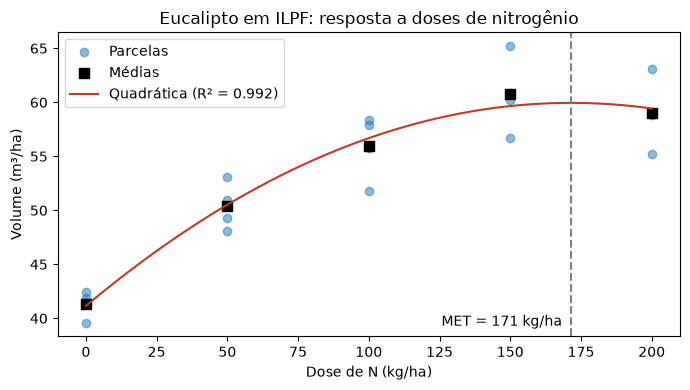

In [30]:
x = np.linspace(0, 200, 200)
medias_d = doses.groupby("dose_n_kg_ha")["volume_m3_ha"].mean()
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(doses["dose_n_kg_ha"], doses["volume_m3_ha"], alpha=0.5, label="Parcelas")
ax.scatter(medias_d.index, medias_d.values, marker="s", s=60, color="black", label="Médias")
ax.plot(x, b0 + b1 * x + b2 * x ** 2, color="#c0392b", label=f"Quadrática (R² = {r2_quad:.3f})")
ax.axvline(MET, linestyle="--", color="gray")
ax.text(MET - 3, ax.get_ylim()[0] + 1, f"MET = {MET:.0f} kg/ha", ha="right")
ax.set_xlabel("Dose de N (kg/ha)")
ax.set_ylabel("Volume (m³/ha)")
ax.set_title("Eucalipto em ILPF: resposta a doses de nitrogênio")
ax.legend()
plt.tight_layout()
plt.show()

**Interpretação:** o efeito quadrático é significativo e os desvios não são, então a parábola descreve bem a resposta (R² = 0,99). A produção máxima ocorre por volta de **171 kg/ha de N**. Lembre que a **dose econômica** costuma ser menor que a MET, pois depende do preço do adubo e da madeira.

---
## 6. Contagem de pragas: quando os pressupostos falham

**Experimento:** 4 manejos (convencional, SAF simples, SAF biodiverso, pousio) × 6 armadilhas em DIC. Resposta: número de insetos-praga por armadilha.

**Por que este exemplo?** Dados de **contagem** quase nunca são normais e, onde a média é maior, a variação também é maior. Isso viola a **homogeneidade das variâncias**. Vamos ver: (1) a falha, (2) a correção por **transformação raiz(x + 0,5)** e (3) a alternativa **não paramétrica** (Kruskal-Wallis).

In [31]:
pragas = carregar("dic_contagem_pragas")
display(pragas.head())
print(pragas.groupby("manejo")["insetos_praga"].agg(["mean", "var"]).round(2))
print("\nRepare: a variância cresce junto com a média (típico de contagens).")

Lido de: ../dados/dic_contagem_pragas.csv


,manejo,repeticao,insetos_praga
0,convencional,1,9
1,convencional,2,12
2,convencional,3,33
3,convencional,4,31
4,convencional,5,24


                 mean    var
manejo                      
convencional    21.17  97.37
pousio          13.83  18.57
saf_biodiverso   2.50   4.30
saf_simples      9.83  31.37

Repare: a variância cresce junto com a média (típico de contagens).


### 6.1 ANOVA nos dados originais: veja o diagnóstico

In [32]:
mod_pragas = smf.ols("insetos_praga ~ C(manejo)", data=pragas).fit()
tab = quadro_anova(mod_pragas)
display(tab)
cv_pragas = cv(mod_pragas, pragas["insetos_praga"])
print(f"CV = {cv_pragas:.2f} %   <- muito alto!")
sw, bt, lv = pressupostos(mod_pragas, pragas, "insetos_praga", "manejo")
conferir["6 Pragas: F original"] = tab.loc["manejo", "Fc"]
conferir["6 Pragas: CV original %"] = cv_pragas
conferir["6 Pragas: Bartlett p original"] = bt

,GL,SQ,QM,Fc,Pr>Fc
manejo,3.0,1093.3333,364.4444,9.6159,0.0004
Resíduo,20.0,758.0000,37.9000,NaN,NaN
Total,23.0,1851.3333,NaN,NaN,NaN


CV = 52.03 %   <- muito alto!
Normalidade dos resíduos (Shapiro-Wilk): W = 0.9770, p = 0.8342  -> OK (p > 0,05)
Homogeneidade (Bartlett):                K2 = 9.8566, p = 0.0198  -> VIOLADO (p <= 0,05)
Homogeneidade (Levene, mediana):         W = 5.2177, p = 0.0080  -> VIOLADO (p <= 0,05)


**Diagnóstico:** o teste de Bartlett deu p < 0,05, então **as variâncias não são homogêneas** e o CV passa de 50%. A ANOVA "crua" não é confiável.

### 6.2 Transformação raiz(x + 0,5)
**O que este código faz:** cria uma nova coluna com a raiz quadrada da contagem + 0,5 (o 0,5 evita problemas com zeros), refaz ANOVA, pressupostos, CV e Tukey nessa escala.

In [33]:
pragas["raiz"] = np.sqrt(pragas["insetos_praga"] + 0.5)
mod_raiz = smf.ols("raiz ~ C(manejo)", data=pragas).fit()
tab = quadro_anova(mod_raiz)
display(tab)
cv_raiz = cv(mod_raiz, pragas["raiz"])
print(f"CV = {cv_raiz:.2f} %")
sw, bt, lv = pressupostos(mod_raiz, pragas, "raiz", "manejo")
print()
print(pairwise_tukeyhsd(pragas["raiz"], pragas["manejo"], alpha=0.05))
display(tukey_letras(pragas, "raiz", "manejo", mod_raiz.mse_resid, mod_raiz.df_resid))
conferir["6 Pragas: F raiz"] = tab.loc["manejo", "Fc"]
conferir["6 Pragas: CV raiz %"] = cv_raiz
conferir["6 Pragas: Bartlett p raiz"] = bt

,GL,SQ,QM,Fc,Pr>Fc
manejo,3.0,27.5231,9.1744,13.6617,4.4599e-05
Resíduo,20.0,13.4308,0.6715,NaN,NaN
Total,23.0,40.9538,NaN,NaN,NaN


CV = 25.14 %
Normalidade dos resíduos (Shapiro-Wilk): W = 0.9632, p = 0.5057  -> OK (p > 0,05)
Homogeneidade (Bartlett):                K2 = 2.3816, p = 0.4971  -> OK (p > 0,05)
Homogeneidade (Levene, mediana):         W = 1.8801, p = 0.1655  -> OK (p > 0,05)



        Multiple Comparison of Means - Tukey HSD, FWER=0.05         
    group1         group2     meandiff p-adj   lower   upper  reject
--------------------------------------------------------------------
  convencional         pousio  -0.7944 0.3601 -2.1186  0.5299  False
  convencional saf_biodiverso  -2.9208    0.0  -4.245 -1.5965   True
  convencional    saf_simples  -1.4246 0.0322 -2.7489 -0.1004   True
        pousio saf_biodiverso  -2.1264 0.0012 -3.4506 -0.8022   True
        pousio    saf_simples  -0.6303 0.5542 -1.9545   0.694  False
saf_biodiverso    saf_simples   1.4961 0.0233  0.1719  2.8204   True
--------------------------------------------------------------------


Tukey a 5%: DMS = 1.3242 (q = 3.958, QM resíduo = 0.6715, GL = 20, n = 6)


,Média,Grupo
manejo,,
convencional,4.545,a
pousio,3.750,ab
saf_simples,3.120,b
saf_biodiverso,1.624,c


### 6.3 Alternativa não paramétrica: Kruskal-Wallis
**O que este código faz:** o Kruskal-Wallis compara os manejos usando a **ordem (posto)** dos valores, sem exigir normalidade nem variâncias iguais.

In [34]:
grupos = [g["insetos_praga"].to_numpy(dtype=float) for _, g in pragas.groupby("manejo")]
kw = stats.kruskal(*grupos)
print(f"Kruskal-Wallis: H = {kw.statistic:.3f}, GL = {len(grupos) - 1}, p = {kw.pvalue:.6f}")
conferir["6 Pragas: Kruskal H"] = kw.statistic
conferir["6 Pragas: Kruskal p"] = kw.pvalue

Kruskal-Wallis: H = 15.201, GL = 3, p = 0.001653


### 6.4 Gráfico: antes e depois da transformação

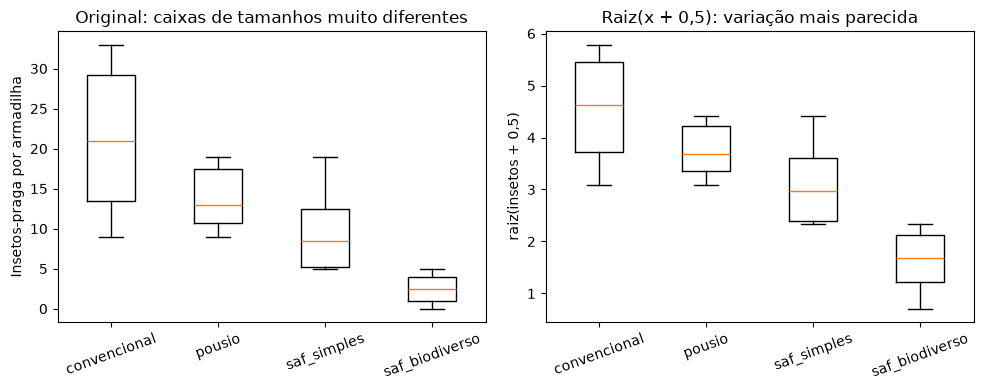

In [35]:
ordem_m = ["convencional", "pousio", "saf_simples", "saf_biodiverso"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot([pragas.loc[pragas.manejo == m, "insetos_praga"] for m in ordem_m])
axes[0].set_title("Original: caixas de tamanhos muito diferentes")
axes[0].set_ylabel("Insetos-praga por armadilha")
axes[1].boxplot([pragas.loc[pragas.manejo == m, "raiz"] for m in ordem_m])
axes[1].set_title("Raiz(x + 0,5): variação mais parecida")
axes[1].set_ylabel("raiz(insetos + 0,5)")
for ax in axes:
    ax.set_xticks(range(1, 5), ordem_m, rotation=20)
plt.tight_layout()
plt.show()

**Interpretação:** depois da transformação, os pressupostos passam a ser atendidos e o efeito dos manejos fica ainda mais claro. O **SAF biodiverso** tem significativamente menos pragas que todos os outros manejos, e o convencional tem mais que o SAF simples. O Kruskal-Wallis chega à mesma conclusão (p ≈ 0,002). Ao apresentar, mostre as **médias originais** (insetos/armadilha) com as letras obtidas na escala transformada.

> Uma alternativa mais avançada para contagens é o **modelo linear generalizado (GLM) Poisson ou binomial negativo**. Vale pedir à IA que explique quando usar.

---
## 7. Conferência com o gabarito do R (`ExpDes.pt`)

**O que este código faz:** compara os números calculados aqui em Python com os obtidos no R (arquivo `dados/gabarito_resultados.txt`, gerado por `notebooks/analise_exemplos.R`). **É exatamente isso que você deve fazer com qualquer resultado de IA: conferir com uma fonte confiável.**

Pequenas diferenças na 3ª ou 4ª casa decimal vêm de arredondamento na impressão do R (ex.: o R mostra o p do DBC como 0.0000017; o valor exato é 1,66 × 10⁻⁶).

In [36]:
gabarito_R = {
    "1 DIC: F substrato": 34.573, "1 DIC: p substrato": 2.0868e-07, "1 DIC: CV %": 6.1,
    "1 DIC: Shapiro p": 0.8071113, "1 DIC: Bartlett p": 0.09455033,
    "2 DBC: F cultivar": 34.686, "2 DBC: p cultivar": 0.0000017, "2 DBC: F bloco": 7.731,
    "2 DBC: CV %": 5.04, "2 DBC: Shapiro p": 0.313313,
    "3 Fatorial: F especie": 111.098, "3 Fatorial: F adubacao": 53.064, "3 Fatorial: F interacao": 15.714,
    "3 Fatorial: p interacao": 9.3204e-07, "3 Fatorial: CV %": 8.55, "3 Fatorial: Shapiro p": 0.4999856,
    "3 Fatorial: F esp. d/ mineral": 94.3217, "3 Fatorial: F adub. d/ aroeira": 0.9883,
    "3 Fatorial: p adub. d/ aroeira": 0.3853,
    "4 Subdividida: F sombreamento": 6.477, "4 Subdividida: p sombreamento": 0.031721,
    "4 Subdividida: F bloco": 4.376, "4 Subdividida: F cultivar": 78.611,
    "4 Subdividida: F interacao": 5.968, "4 Subdividida: p interacao": 0.003075,
    "4 Subdividida: CV1 %": 9.472102, "4 Subdividida: CV2 %": 3.724808,
    "4 Subdividida: F somb. d/ Topazio": 12.128865, "4 Subdividida: F cult. d/ 30%": 7.622929,
    "5 Doses: F tratamento": 32.55, "5 Doses: CV %": 5.14, "5 Doses: F efeito linear": 110.27,
    "5 Doses: F efeito quadratico": 18.9, "5 Doses: R2 quadratico": 0.992103, "5 Doses: b1": 0.2192,
    "5 Doses: MET kg/ha": 171.4,
    "6 Pragas: F original": 9.6159, "6 Pragas: CV original %": 52.03, "6 Pragas: Bartlett p original": 0.01982546,
    "6 Pragas: F raiz": 13.662, "6 Pragas: CV raiz %": 25.14, "6 Pragas: Bartlett p raiz": 0.4970718,
    "6 Pragas: Kruskal H": 15.201, "6 Pragas: Kruskal p": 0.001653,
}
comp = pd.DataFrame({"Python": pd.Series(conferir), "R (gabarito)": pd.Series(gabarito_R)})
comp["Diferença relativa %"] = 100 * (comp["Python"] - comp["R (gabarito)"]).abs() / comp["R (gabarito)"].abs()
# critério: diferença relativa < 1% OU diferença absoluta < 1e-6 (p-valores minúsculos que o R imprime arredondados)
comp["Bate?"] = np.where((comp["Diferença relativa %"] < 1) | ((comp["Python"] - comp["R (gabarito)"]).abs() < 1e-6), "sim", "NÃO")
with pd.option_context("display.float_format", "{:.6g}".format):
    display(comp)
print(f"\n{(comp['Bate?'] == 'sim').sum()} de {len(comp)} valores conferem com o R.")

,Python,R (gabarito),Diferença relativa %,Bate?
1 DIC: F substrato,34.5731,34.573,0.000153403,sim
1 DIC: p substrato,2.08683e-07,2.0868e-07,0.0014571,sim
1 DIC: CV %,6.09552,6.1,0.073524,sim
1 DIC: Shapiro p,0.807111,0.807111,7.28032e-07,sim
1 DIC: Bartlett p,0.0945503,0.0945503,4.8318e-06,sim
2 DBC: F cultivar,34.6863,34.686,0.000815047,sim
2 DBC: p cultivar,1.65971e-06,1.7e-06,2.36975,sim
2 DBC: F bloco,7.73074,7.731,0.00331986,sim
2 DBC: CV %,5.04205,5.04,0.0406204,sim
2 DBC: Shapiro p,0.313313,0.313313,1.10386e-05,sim



44 de 44 valores conferem com o R.


---
## 8. (Opcional) A mesma análise em R, dentro do Colab

**O que este código faz:** o Colab também roda **R** dentro de um notebook Python, pela ponte `rpy2`. A primeira célula ativa a ponte; a segunda (que começa com `%%R`) é **código R puro**, usando o pacote `ExpDes.pt`, padrão em agronomia no Brasil.

> Essas células **não** foram executadas na preparação deste material. No Colab, a instalação do `ExpDes.pt` leva alguns minutos. Os dados precisam estar na pasta `dados/` ou em `/content` (ajuste o caminho).

In [ ]:
# Ativa a "ponte" Python -> R (o rpy2 já vem instalado no Colab)
%load_ext rpy2.ipython

In [ ]:
%%R
if (!requireNamespace("ExpDes.pt", quietly = TRUE)) install.packages("ExpDes.pt")
library(ExpDes.pt)

pasta <- if (dir.exists("dados")) "dados" else if (dir.exists("../dados")) "../dados" else "/content"
ler <- function(nome) read.csv(file.path(pasta, paste0(nome, ".csv")))

# DIC: substratos de mudas
d <- ler("dic_mudas")
dic(d$substrato, d$altura_cm, quali = TRUE, mcomp = "tukey")

# Fatorial com desdobramento automático
d <- ler("fatorial_adubacao")
fat2.dic(d$especie, d$adubacao, d$massa_seca_g, quali = c(TRUE, TRUE),
         mcomp = "tukey", fac.names = c("Especie", "Adubacao"))

# Parcela subdividida (erro a e erro b automáticos)
d <- ler("parcela_sub_cafe_sombra")
psub2.dbc(d$sombreamento_pct, d$cultivar, d$bloco, d$produtividade_sc_ha,
          quali = c(FALSE, TRUE), mcomp = "tukey", fac.names = c("Sombreamento", "Cultivar"))

---
## 9. Peça ao Gemini no Colab (Data Science Agent)

No Colab, clique no botão **Gemini** (✦, no canto inferior ou superior direito) e escreva o pedido em português. O **Data Science Agent** cria as células de código, executa e explica. **Antes**, carregue o arquivo no painel 📁 Arquivos. Depois, **confira** os números com este notebook (seção 7).

Copie e cole um dos pedidos abaixo:

**1. DIC (mudas)**
```
Você é um estatístico experimental da área agroflorestal. Carregue o arquivo dic_mudas.csv. É um experimento em DIC com 5 substratos (coluna substrato) e 4 repetições; a variável resposta é altura_cm. Faça: (1) ANOVA com quadro completo (GL, SQ, QM, F, p); (2) teste de Shapiro-Wilk nos resíduos e Bartlett para homogeneidade; (3) CV%; (4) teste de Tukey a 5% com letras; (5) gráfico de barras com as letras. Explique os resultados em português simples, como para um produtor rural.
```

**2. DBC (milho)**
```
Carregue dbc_milho.csv. É um experimento em blocos casualizados (DBC): 5 cultivares (coluna cultivar) em 4 blocos (coluna bloco); resposta produtividade_kg_ha. Faça a ANOVA incluindo o efeito de bloco, verifique os pressupostos, calcule o CV% e aplique Tukey a 5% usando o quadrado médio do resíduo da ANOVA do DBC (não use um Tukey que ignore os blocos). Mostre o código e diga se valeu a pena usar blocos.
```

**3. Fatorial com desdobramento**
```
Carregue fatorial_adubacao.csv: fatorial 3x3 em DIC, fatores especie e adubacao, 4 repetições, resposta massa_seca_g. Faça a ANOVA com interação. Se a interação for significativa a 5%, faça o desdobramento: espécie dentro de cada adubação e adubação dentro de cada espécie, usando o QM do resíduo da ANOVA completa, com Tukey nos casos significativos. Faça um gráfico de interação e interprete.
```

**4. Parcela subdividida**
```
Carregue parcela_sub_cafe_sombra.csv. É um experimento em parcelas subdivididas em DBC: parcela = sombreamento_pct (0, 30, 50%), subparcela = cultivar de café, 4 blocos, resposta produtividade_sc_ha. Faça a ANOVA com dois erros: erro (a) = bloco x sombreamento para testar sombreamento e bloco; erro (b) = resíduo para cultivar e interação. Mostre o CV da parcela e da subparcela. Não analise como fatorial simples. Depois desdobre a interação e faça um gráfico.
```

**5. Regressão de doses**
```
Carregue doses_nitrogenio.csv: doses de N (dose_n_kg_ha = 0, 50, 100, 150, 200) em DIC com 4 repetições; resposta volume_m3_ha. Como a dose é quantitativa, NÃO use Tukey. Faça a ANOVA, ajuste regressões linear e quadrática, teste os efeitos linear, quadrático e os desvios da regressão com o QM do resíduo, informe o R², a equação e a dose de máxima eficiência técnica (MET = -b1/(2*b2)). Faça o gráfico com a curva e a MET marcada.
```

**6. Pressupostos violados (contagens)**
```
Carregue dic_contagem_pragas.csv: DIC com 4 manejos (coluna manejo) e 6 repetições; resposta insetos_praga (contagem). Faça a ANOVA e teste os pressupostos (Shapiro-Wilk e Bartlett). Se algum pressuposto falhar, explique por que isso é comum em contagens, aplique a transformação raiz(x + 0,5) e refaça a análise com Tukey, e rode também o teste de Kruskal-Wallis. Compare as conclusões e faça boxplots antes e depois da transformação.
```

> **Checklist depois da resposta da IA:** o GL do resíduo está certo? Ela usou o erro certo (bloco, erro a)? Mostrou o CV? Testou pressupostos? Os números batem com o gabarito? Peça sempre: *"mostre o código que você usou"*.